##  Heart Disease Prediction – Keras / TensorFlow
**Dataset:** `heart.csv` | **Target:** `HeartDisease` (1 = bimari hai, 0 = nahi)

Steps: Data dekho → Saaf karo → Encode + Split + Scale → Model banao → Train karo → Check karo

## 1. Libraries

In [48]:
import numpy as np                                    # numbers ke liye
import pandas as pd                                   # data table ke liye
import matplotlib.pyplot as plt                       # chart ke liye
from tensorflow import keras                          # Keras library
from tensorflow.keras import layers                   # layers (Dense)
from tensorflow.keras.utils import to_categorical     # target ko one-hot banane ke liye
from sklearn.model_selection import train_test_split  # train/test split
from sklearn.preprocessing import StandardScaler      # scaling
from sklearn.metrics import precision_score, recall_score, confusion_matrix  # scores

## 2. Data load karo aur dekho

In [49]:
df = pd.read_csv("heart.csv")

In [50]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [52]:
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [53]:
df['HeartDisease'].value_counts()           # 0 aur 1 kitne hain

,count
HeartDisease,
1,508
0,410


## 3. Data Cleaning

In [54]:
# RestingBP 0 nahi ho sakta, ye sirf 1 row mein hai, isliye hata do
df = df[df['RestingBP'] > 0]

In [55]:
# Cholesterol 0 bhi galat hai (missing data). Isko baaki values ke median se bhar do
median = df[df['Cholesterol'] > 0]['Cholesterol'].median()   # 0 chhodke median nikalo
df['Cholesterol'] = df['Cholesterol'].replace(0, median)     # 0 ki jagah median daalo

## 4. Encoding, Split aur Scaling

In [56]:
# Text columns ko numbers mein badlo (one-hot encoding)
df = pd.get_dummies(df, columns=['Sex', 'ChestPainType', 'RestingECG',
                                 'ExerciseAngina', 'ST_Slope'], dtype=float)

In [57]:
# X = input, y = target
X = df.drop('HeartDisease', axis=1).values
y = df['HeartDisease'].values
print("Input features ki sankhya:", X.shape[1])

Input features ki sankhya: 20


In [58]:
# Target ko one-hot banao: 0 -> [1, 0], 1 -> [0, 1]
y_onehot = to_categorical(y, num_classes=2)

In [59]:
# 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot, test_size=0.2, random_state=42)

In [60]:
# Scaling: train par seekho (fit), test par sirf lagao (transform)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 5. Model banao (20 input → 16 → 8 → 4 → 2 output)

In [61]:
model = keras.Sequential([
    layers.Input(shape=(X.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(4, activation='relu')
])

In [62]:
model = keras.Sequential([
    layers.Input(shape=(X.shape[1],)),        # input layer
    layers.Dense(16, activation='relu'),      # hidden layer 1
    layers.Dense(8, activation='relu'),       # hidden layer 2
    layers.Dense(4, activation='relu'),       # hidden layer 3
    layers.Dense(2, activation='sigmoid')     # output layer (2 nodes)
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),  # optimizer
              loss='binary_crossentropy',                            # loss
              metrics=['accuracy'])                                  # accuracy dekhni hai

## 6. Training
`validation_split=0.2` ka matlab: train data ka 20% sirf check karne ke liye alag rakha, taaki overfitting pata chale.

In [42]:
history = model.fit(X_train, y_train, epochs=50, validation_split=0.2, verbose=1)

Epoch 1/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.5700 - loss: 0.6630 - val_accuracy: 0.6054 - val_loss: 0.6527
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6741 - loss: 0.6243 - val_accuracy: 0.6531 - val_loss: 0.6224
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7577 - loss: 0.5899 - val_accuracy: 0.7279 - val_loss: 0.5921
Epoch 4/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7952 - loss: 0.5521 - val_accuracy: 0.7687 - val_loss: 0.5603
Epoch 5/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8191 - loss: 0.5078 - val_accuracy: 0.7687 - val_loss: 0.5302
Epoch 6/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8311 - loss: 0.4617 - val_accuracy: 0.7755 - val_loss: 0.5032
Epoch 7/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8396 - loss: 0.4208 - val_accuracy: 0.8027 - val_loss: 0.4830
Epoch 8/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8447 - loss: 0.3876 - val_accuracy: 0.8095 - val_loss

## 7. Loss aur Accuracy ka chart
Agar train loss girta rahe par validation loss badhne lage, toh model overfit ho raha hai.

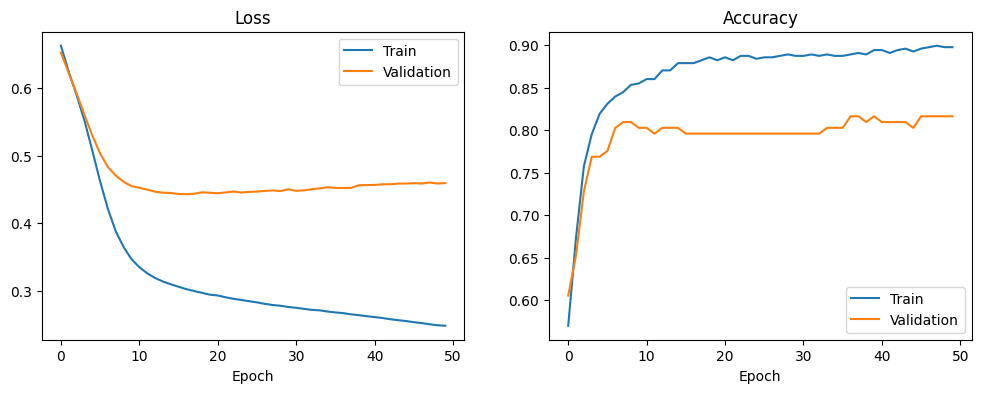

In [43]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)                                      # pehla chart
plt.plot(history.history['loss'], label='Train')          # train loss
plt.plot(history.history['val_loss'], label='Validation') # validation loss
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)                                          # doosra chart
plt.plot(history.history['accuracy'], label='Train')          # train accuracy
plt.plot(history.history['val_accuracy'], label='Validation') # validation accuracy
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.show()

## 8. Test data par result

In [44]:
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print("Test Accuracy:", round(acc, 2))

Test Accuracy: 0.84


In [45]:
# one-hot se wapas 0/1 banane ke liye argmax
y_pred = np.argmax(model.predict(X_test), axis=1)   # model ka jawab
y_true = np.argmax(y_test, axis=1)                  # asli jawab

precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
print("Precision:", round(precision, 2))
print("Recall   :", round(recall, 2))

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Precision: 0.89
Recall   : 0.84


In [46]:
# Confusion matrix: [[sahi healthy, galat alarm], [bimar miss, sahi bimar]]
print(confusion_matrix(y_true, y_pred))

[[60 12]
 [18 94]]


                 Predicted
              Healthy(0)  Disease(1)
Actual
Healthy(0)  [   62          10   ]
Disease(1)  [   15          97   ]

## 9. Final Conclusion

In [47]:
print("Accuracy :", round(acc, 2))
print("Precision:", round(precision, 2))
print("Recall   :", round(recall, 2))

Accuracy : 0.84
Precision: 0.89
Recall   : 0.84


- **Dataset:** Heart Disease, target `HeartDisease`.
- **Preprocessing:** galat 0 values theek ki, one-hot encoding (20 features), StandardScaler, 80-20 split.
- **Model:** 20 input → 16 → 8 → 4 (ReLU) → 2 output (Sigmoid), Adam, Binary Crossentropy, 50 epochs.
- **Precision** = model ne "bimar" bola toh kitni baar sahi tha.
- **Recall** = asli bimaron mein se kitne pakde. Medical mein ye zyada important hai, kyunki bimar ko miss karna risky hai.
- **Overfitting:** upar ke chart se dekho ki validation loss badh raha hai ya nahi.